## importing data

In [1]:
import pandas as pd
from spacepy import pycdf
import numpy as np
from scipy.signal import welch
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from matplotlib.colors import LogNorm
from scipy.signal import spectrogram
from matplotlib.colors import LogNorm
from scipy.signal import spectrogram

In [2]:

# Load the CDF file
cdf_path = '/home/draksha/pydata/mms1/fgm/srvy/l2/2015/10/mms1_fgm_srvy_l2_20151028_v4.18.0.cdf'
cdf = pycdf.CDF(cdf_path)
cdf


<CDF:
Epoch: CDF_TIME_TT2000 [1051008]
Epoch_state: CDF_TIME_TT2000 [2883]
label_b_bcs: CDF_CHAR*10 [4] NRV
label_b_dmpa: CDF_CHAR*10 [4] NRV
label_b_gse: CDF_CHAR*10 [4] NRV
label_b_gsm: CDF_CHAR*11 [4] NRV
label_r_gse: CDF_CHAR*10 [4] NRV
label_r_gsm: CDF_CHAR*10 [4] NRV
mms1_fgm_b_bcs_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_dmpa_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gse_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gsm_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_bdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_etemp_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_flag_srvy_l2: CDF_UINT4 [1051008]
mms1_fgm_hirange_srvy_l2: CDF_UINT1 [1051008]
mms1_fgm_mode_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_r_gse_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_r_gsm_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_rdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_stemp_srvy_l2: CDF_FLOAT [1051008]
represent_vec_tot: CDF_CHAR*1 [4] NRV
>

In [3]:
# Extract the magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
b_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
b_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
b_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]
b_t = cdf['mms1_fgm_b_gse_srvy_l2'][:,3]
b_x

array([81.73284, 81.72514, 81.72964, ..., 86.88986, 86.86479, 86.90699],
      dtype=float32)

In [4]:
# Combine into a DataFrame
df = pd.DataFrame({
    'datetime': datetime,
    'b_x': b_x,
    'b_y': b_y,
    'b_z': b_z,
    'b_t':b_t
})

# Drop any NaN values (if any) to avoid errors
df.dropna(inplace=True)

# Calculate sampling frequency from the datetime data
time_diff = np.diff(df['datetime']).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
sampling_freq = 1 / np.mean(time_diff)  # Hz

# Extract the magnetic field components as NumPy arrays
b_x = df['b_x'].values
b_y = df['b_y'].values
b_z = df['b_z'].values
b_t = df['b_t'].values
df.to_csv('magnetic_data.csv')

In [5]:
b_x

array([81.73284, 81.72514, 81.72964, ..., 86.88986, 86.86479, 86.90699],
      dtype=float32)

In [6]:
import numpy as np
average_b_t = np.mean(df['b_t'].values)
print(average_b_t)


363.47833


In [7]:
df

,datetime,b_x,b_y,b_z,b_t
0,2015-10-28 00:00:10.963242,81.732841,-181.288544,445.587585,487.948853
1,2015-10-28 00:00:11.088244,81.725143,-181.284271,445.566803,487.927032
2,2015-10-28 00:00:11.213246,81.729637,-181.289795,445.544617,487.909576
3,2015-10-28 00:00:11.338247,81.757286,-181.283447,445.520325,487.889648
4,2015-10-28 00:00:11.463249,81.760918,-181.282104,445.496582,487.868073
...,...,...,...,...,...
1051003,2015-10-29 00:00:11.490561,86.900932,-159.191711,395.277039,434.899658
1051004,2015-10-29 00:00:11.615562,86.917961,-159.204590,395.254395,434.887177
1051005,2015-10-29 00:00:11.740564,86.889862,-159.177521,395.238434,434.857178
1051006,2015-10-29 00:00:11.865566,86.864792,-159.139099,395.226074,434.826874


## Magnetic feild components in gse coordinate

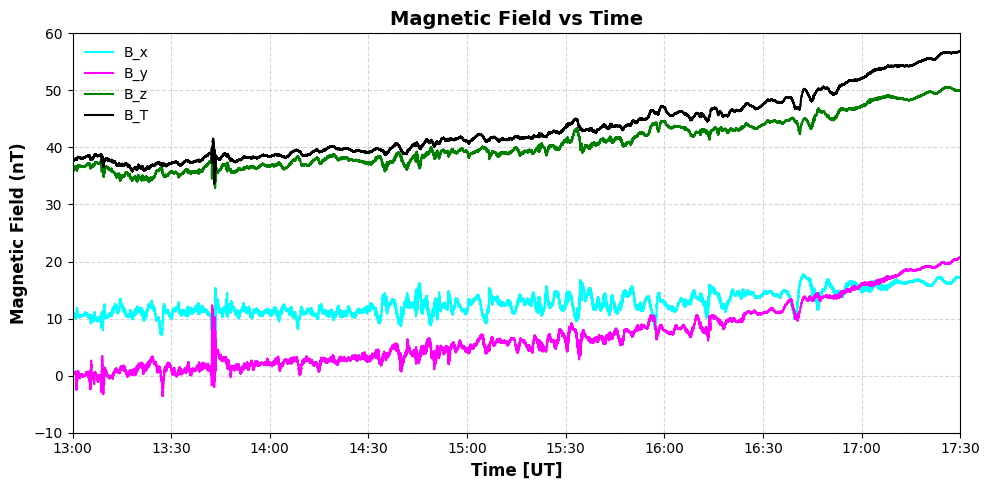

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(df['datetime'], b_x, label='B_x', color='cyan')
plt.plot(df['datetime'], b_y, label='B_y', color='magenta')
plt.plot(df['datetime'], b_z, label='B_z', color='green')
plt.plot(df['datetime'], b_t, label='B_T', color='black')

# Set y-axis limits
plt.ylim(-10, 60)

# Define x-axis limits
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
plt.xlim(start_time, end_time)

# Add labels and title
plt.xlabel('Time [UT]', fontsize=12, fontweight='bold')  # Updated x-label
plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
plt.title('Magnetic Field vs Time', fontsize=14, fontweight='bold')

# Rotate x-axis labels for better readability
plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)

# Format the x-axis labels (optional, ensures clear UTC format)
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%H:%M'))  # Only show HH:MM in UT

# Add grid and legend
plt.grid(linestyle='--', alpha=0.5)
plt.legend(frameon=False, fontsize=10)

# Show the plot
plt.tight_layout()
plt.savefig('/home/draksha/Downloads/Changed_magnetic_filed.png')
plt.show()


In [9]:
# Filter data for the desired time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]


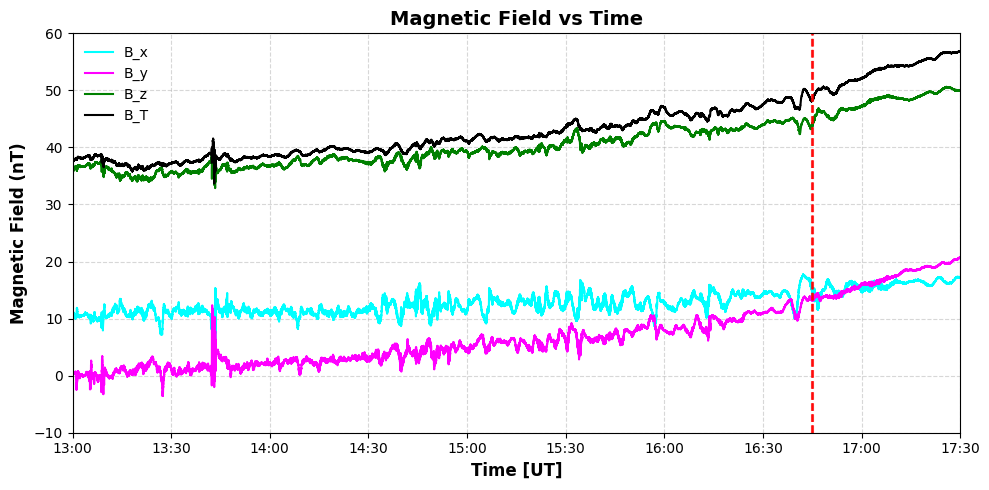

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(df['datetime'], b_x, label='B_x', color='cyan')
plt.plot(df['datetime'], b_y, label='B_y', color='magenta')
plt.plot(df['datetime'], b_z, label='B_z', color='green')
plt.plot(df['datetime'], b_t, label='B_T', color='black')

# Set y-axis limits
plt.ylim(-10, 60)

# Define x-axis limits
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
plt.xlim(start_time, end_time)

# Add vertical lines at specified times
vline_times = ['2015-10-28 16:45:03', '2015-10-28 16:45:06']
for vtime in vline_times:
    plt.axvline(pd.Timestamp(vtime), color='red', linestyle='--', linewidth=1.5, alpha=0.8)

# Add labels and title
plt.xlabel('Time [UT]', fontsize=12, fontweight='bold')  # Updated x-label
plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
plt.title('Magnetic Field vs Time', fontsize=14, fontweight='bold')

# Rotate x-axis labels for better readability
plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)

# Format the x-axis labels (optional, ensures clear UTC format)
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%H:%M'))  # Only show HH:MM in UT

# Add grid and legend
plt.grid(linestyle='--', alpha=0.5)
plt.legend(frameon=False, fontsize=10)

# Show the plot
plt.tight_layout()
plt.savefig('/home/draksha/Downloads/Changed_magnetic_filed.png')
plt.show()


## Power spectrum of Bx component

In [24]:
np.mean(filtered_df['b_t'])

np.float32(50.01135)

In [11]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt


# Extract magnetic field and time values
b_x_filtered = filtered_df['b_x'].values
time_filtered = filtered_df['datetime']

# Sampling frequency
time_diff = np.diff(time_filtered).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
sampling_freq = 16  # Hz (adjust if necessary)

# FFT
n = len(b_x_filtered)  # Number of samples
fft_result = np.fft.fft(b_x_filtered) / n  # Normalize FFT by number of samples
fft_freqs = np.fft.fftfreq(n, d=1/sampling_freq)  # Compute FFT frequencies
fft_power = (np.abs(fft_result) ** 2) * n  # Compute Power Spectrum

# Use only the positive frequencies
positive_freqs = fft_freqs[:n//2]
positive_power = fft_power[:n//2]

# # Plot Power Spectrum
# plt.figure(figsize=(10, 5))
# plt.loglog(positive_freqs, positive_power, color='blue', label='Power Spectrum')


# # Add vertical lines at 0.5 Hz and 0.8 Hz
# plt.axvline(x=0.25, color='purple', linestyle='--', linewidth=1, label='Peak at 0.285 Hz')
# plt.axvline(x=0.68, color='orange', linestyle='--', linewidth=1, label='Peak at 0.65 Hz')


# # Add labels and title
# plt.xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
# plt.ylabel('Power (nT^2/Hz)', fontsize=12, fontweight='bold')
# plt.title('Power Spectrum of B_x', fontsize=14, fontweight='bold')

# # Add grid and legend
# plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)
# plt.legend(frameon=False, fontsize=10)

# # Show the plot
# plt.tight_layout()
# plt.show()


In [12]:
n

217532

## Power Spectrum of magnetic field Components

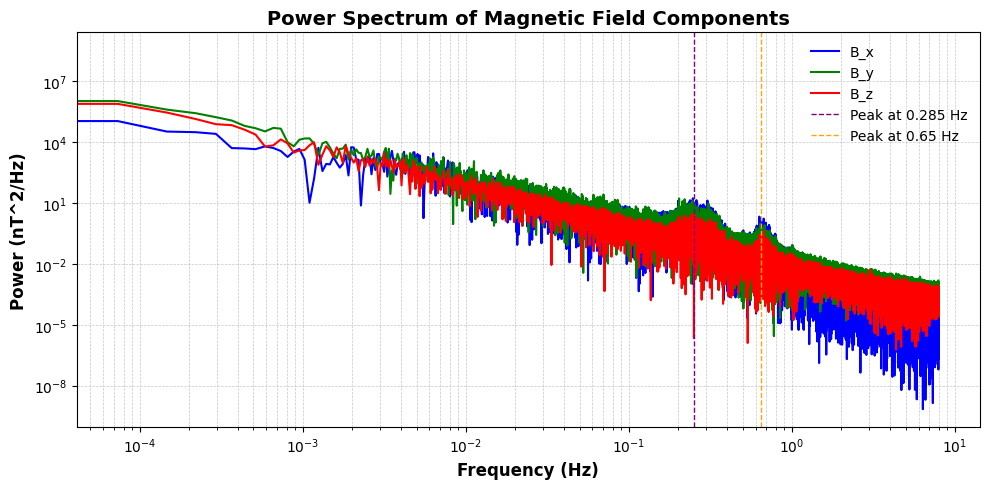

In [13]:

# Filter data for the desired time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# Extract magnetic field and time values for all three components
b_x_filtered = filtered_df['b_x'].values
b_y_filtered = filtered_df['b_y'].values
b_z_filtered = filtered_df['b_z'].values
time_filtered = filtered_df['datetime']

# # Sampling frequency
# time_diff = np.diff(time_filtered).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
# sampling_freq = 1 / np.median(time_diff)  # Use median to reduce outlier effects

# Function to compute FFT and Power Spectrum
def compute_fft(b_field):
    n = len(b_field)  # Number of samples
    fft_result = np.fft.fft(b_field) / n  # Normalize FFT by number of samples
    fft_freqs = np.fft.fftfreq(n, d=1/sampling_freq)  # Compute FFT frequencies
    fft_power = (np.abs(fft_result) ** 2) * n  # Compute Power Spectrum with proper scaling
    return fft_freqs, fft_power

# Compute FFT and Power Spectrum for all three components
fft_freqs, power_b_x = compute_fft(b_x_filtered)
_, power_b_y = compute_fft(b_y_filtered)
_, power_b_z = compute_fft(b_z_filtered)

# Use only the positive frequencies
positive_freqs = fft_freqs[:len(fft_freqs)//2]
positive_power_b_x = power_b_x[:len(power_b_x)//2]
positive_power_b_y = power_b_y[:len(power_b_y)//2]
positive_power_b_z = power_b_z[:len(power_b_z)//2]

# Plot Power Spectrum for all three components
plt.figure(figsize=(10, 5))
plt.loglog(positive_freqs, positive_power_b_x, color='blue', label='B_x')
plt.loglog(positive_freqs, positive_power_b_y, color='green', label='B_y')
plt.loglog(positive_freqs, positive_power_b_z, color='red', label='B_z')

# Add vertical lines at 0.5 Hz and 0.8 Hz
plt.axvline(x=0.25, color='purple', linestyle='--', linewidth=1, label='Peak at 0.285 Hz')
plt.axvline(x=0.65, color='orange', linestyle='--', linewidth=1, label='Peak at 0.65 Hz')

# Add labels and title
plt.xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.ylabel('Power (nT^2/Hz)', fontsize=12, fontweight='bold')
plt.title('Power Spectrum of Magnetic Field Components', fontsize=14, fontweight='bold')

# Add grid and legend
plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(frameon=False, fontsize=10)

# Show the plot
plt.tight_layout()
plt.savefig('/home/draksha/Downloads/power_spectrum.png')
plt.show()


## Power Spectrum of Filtered(Bandpass filter) Magnetic Feild Components 

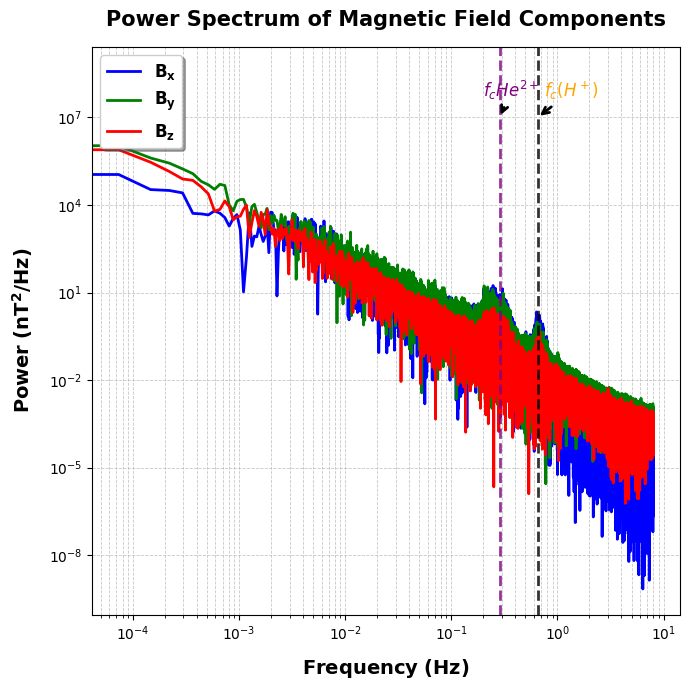

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Filter data for the desired time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# Extract magnetic field components
b_x_filtered = filtered_df['b_x'].values
b_y_filtered = filtered_df['b_y'].values
b_z_filtered = filtered_df['b_z'].values
time_filtered = filtered_df['datetime']

# Sampling frequency
time_diff = np.diff(time_filtered).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
sampling_freq = 1 / np.median(time_diff)  # Use median to reduce outlier effects

# Function to compute FFT and Power Spectrum
def compute_fft(b_field):
    n = len(b_field)  # Number of samples
    fft_result = np.fft.fft(b_field) / n  # Normalize FFT by number of samples
    fft_freqs = np.fft.fftfreq(n, d=1/sampling_freq)  # Compute FFT frequencies
    fft_power = (np.abs(fft_result) ** 2) * n  # Compute Power Spectrum with proper scaling
    return fft_freqs, fft_power

# Compute FFT and Power Spectrum for all three components
fft_freqs, power_b_x = compute_fft(b_x_filtered)
_, power_b_y = compute_fft(b_y_filtered)
_, power_b_z = compute_fft(b_z_filtered)

# Use only the positive frequencies
positive_freqs = fft_freqs[:len(fft_freqs)//2]
positive_power_b_x = power_b_x[:len(power_b_x)//2]
positive_power_b_y = power_b_y[:len(power_b_y)//2]
positive_power_b_z = power_b_z[:len(power_b_z)//2]

# Create square plot with aesthetic improvements
plt.figure(figsize=(7, 7))  # Square aspect ratio

# Plot Power Spectrum for all three components with better contrast
plt.loglog(positive_freqs, positive_power_b_x, color='blue', linewidth=2, label=r'$\mathbf{B_x}$')
plt.loglog(positive_freqs, positive_power_b_y, color='green', linewidth=2, label=r'$\mathbf{B_y}$')
plt.loglog(positive_freqs, positive_power_b_z, color='red', linewidth=2, label=r'$\mathbf{B_z}$')

# Add vertical lines at 0.285 Hz and 0.65 Hz
plt.axvline(x=0.285, color='purple', linestyle='--', linewidth=2, alpha=0.8)
plt.axvline(x=0.65, color='black', linestyle='--', linewidth=2, alpha=0.8)

# Annotate the vertical lines with arrows for clarity
plt.annotate(r'$f_cHe^{2+}$', xy=(0.285, max(positive_power_b_x)*0.3),
             xytext=(0.2, max(positive_power_b_x)*1.5),
             arrowprops=dict(facecolor='purple', arrowstyle='->', linewidth=2),
             fontsize=12, color='purple', fontweight='bold')

plt.annotate(r'$f_c(H^+)$', xy=(0.65, max(positive_power_b_x)*0.3),
             xytext=(0.75, max(positive_power_b_x)*1.5),
             arrowprops=dict(facecolor='orange', arrowstyle='->', linewidth=2),
             fontsize=12, color='orange', fontweight='bold')

# Improve labels and title aesthetics
plt.xlabel(r'$\mathbf{Frequency\ (Hz)}$', fontsize=14, fontweight='bold', labelpad=10)
plt.ylabel(r'$\mathbf{Power\ (nT^2/Hz)}$', fontsize=14, fontweight='bold', labelpad=10)
plt.title('Power Spectrum of Magnetic Field Components', fontsize=15, fontweight='bold', pad=15)

# Improve grid aesthetics
plt.grid(which='both', linestyle='--', linewidth=0.6, alpha=0.7)

# Improve legend aesthetics
plt.legend(frameon=True, fontsize=12, loc='upper left', fancybox=True, shadow=True)

# Adjust layout for better spacing
plt.tight_layout()

# Save and show the plot
plt.savefig('/home/draksha/Downloads/power_spectrum_square.png', dpi=300)
plt.show()


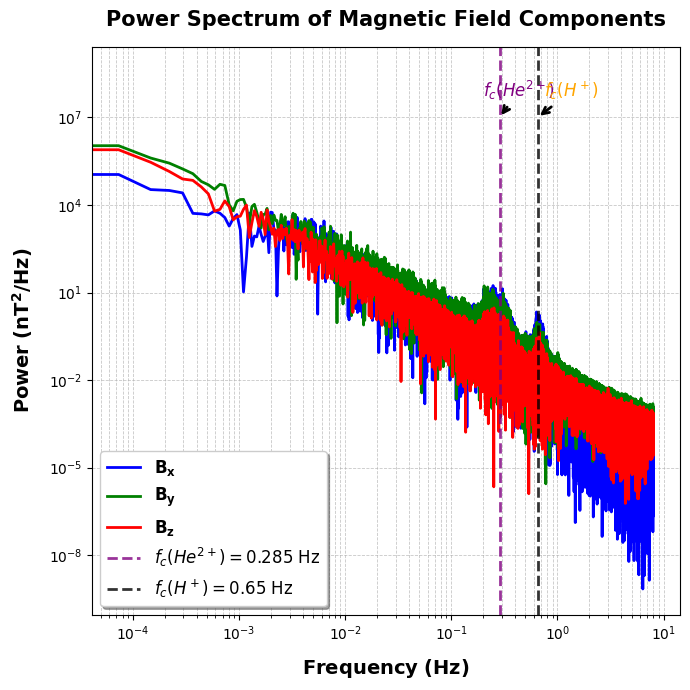

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Filter data for the desired time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# Extract magnetic field components
b_x_filtered = filtered_df['b_x'].values
b_y_filtered = filtered_df['b_y'].values
b_z_filtered = filtered_df['b_z'].values
time_filtered = filtered_df['datetime']

# Sampling frequency
time_diff = np.diff(time_filtered).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
sampling_freq = 1 / np.median(time_diff)  # Use median to reduce outlier effects

# Function to compute FFT and Power Spectrum
def compute_fft(b_field):
    n = len(b_field)  # Number of samples
    fft_result = np.fft.fft(b_field) / n  # Normalize FFT by number of samples
    fft_freqs = np.fft.fftfreq(n, d=1/sampling_freq)  # Compute FFT frequencies
    fft_power = (np.abs(fft_result) ** 2) * n  # Compute Power Spectrum with proper scaling
    return fft_freqs, fft_power

# Compute FFT and Power Spectrum for all three components
fft_freqs, power_b_x = compute_fft(b_x_filtered)
_, power_b_y = compute_fft(b_y_filtered)
_, power_b_z = compute_fft(b_z_filtered)

# Use only the positive frequencies
positive_freqs = fft_freqs[:len(fft_freqs)//2]
positive_power_b_x = power_b_x[:len(power_b_x)//2]
positive_power_b_y = power_b_y[:len(power_b_y)//2]
positive_power_b_z = power_b_z[:len(power_b_z)//2]

# Create square plot with aesthetic improvements
plt.figure(figsize=(7, 7))  # Square aspect ratio

# Plot Power Spectrum for all three components with better contrast
plt.loglog(positive_freqs, positive_power_b_x, color='blue', linewidth=2, label=r'$\mathbf{B_x}$')
plt.loglog(positive_freqs, positive_power_b_y, color='green', linewidth=2, label=r'$\mathbf{B_y}$')
plt.loglog(positive_freqs, positive_power_b_z, color='red', linewidth=2, label=r'$\mathbf{B_z}$')

# Add vertical lines at 0.285 Hz and 0.65 Hz
plt.axvline(x=0.285, color='purple', linestyle='--', linewidth=2, alpha=0.8, label=r'$f_c(He^{2+}) = 0.285$ Hz')
plt.axvline(x=0.65, color='black', linestyle='--', linewidth=2, alpha=0.8, label=r'$f_c(H^+) = 0.65$ Hz')

# Annotate the vertical lines with arrows for clarity
plt.annotate(r'$f_c(He^{2+})$', xy=(0.285, max(positive_power_b_x)*0.3),
             xytext=(0.2, max(positive_power_b_x)*1.5),
             arrowprops=dict(facecolor='purple', arrowstyle='->', linewidth=2),
             fontsize=12, color='purple', fontweight='bold')

plt.annotate(r'$f_c(H^+)$', xy=(0.65, max(positive_power_b_x)*0.3),
             xytext=(0.75, max(positive_power_b_x)*1.5),
             arrowprops=dict(facecolor='orange', arrowstyle='->', linewidth=2),
             fontsize=12, color='orange', fontweight='bold')

# Improve labels and title aesthetics
plt.xlabel(r'$\mathbf{Frequency\ (Hz)}$', fontsize=14, fontweight='bold', labelpad=10)
plt.ylabel(r'$\mathbf{Power\ (nT^2/Hz)}$', fontsize=14, fontweight='bold', labelpad=10)
plt.title('Power Spectrum of Magnetic Field Components', fontsize=15, fontweight='bold', pad=15)

# Improve grid aesthetics
plt.grid(which='both', linestyle='--', linewidth=0.6, alpha=0.7)

# Improve legend aesthetics
plt.legend(frameon=True, fontsize=12, loc='lower left', fancybox=True, shadow=True)

# Adjust layout for better spacing
plt.tight_layout()

# Save and show the plot
plt.savefig('/home/draksha/Downloads/power_spectrum_square.png', dpi=300)
plt.show()


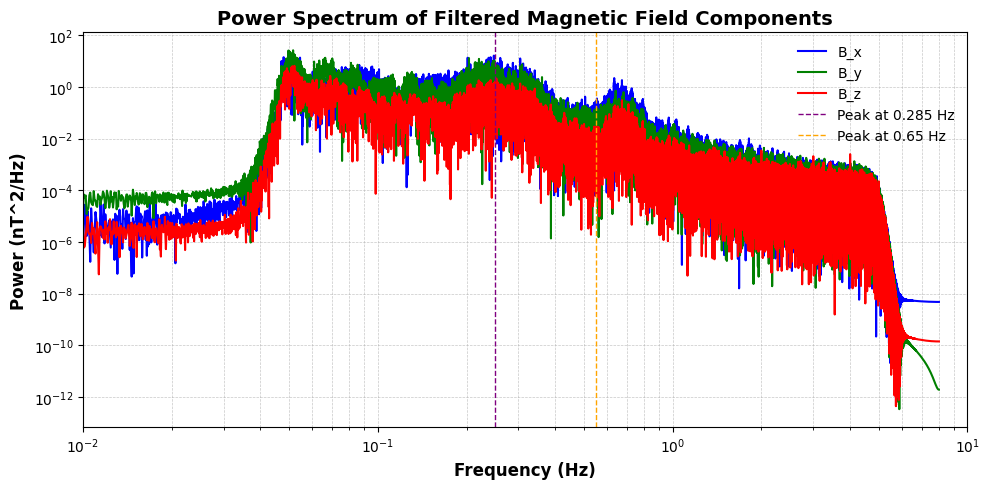

In [16]:
# import numpy as np
# import matplotlib.pyplot as plt
# import pandas as pd


# Define the bandpass filter function
def bandpass_filter(data, lowcut, highcut, sampling_freq, order=8):
    nyquist = 0.5 * sampling_freq
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# # Filter data for the desired time range
# start_time = pd.Timestamp('2015-10-28 13:00:00')
# end_time = pd.Timestamp('2015-10-28 17:30:00')
# filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# # Extract magnetic field and time values for all three components
# b_x_filtered = filtered_df['b_x'].values
# b_y_filtered = filtered_df['b_y'].values
# b_z_filtered = filtered_df['b_z'].values
# time_filtered = filtered_df['datetime']

# # Sampling frequency
# time_diff = np.diff(time_filtered).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
# sampling_freq = 1 / np.mean(time_diff)  # Hz

# Define the bandpass filter frequency range
lowcut = 0.05  # Low frequency (50 mHz)
highcut = 5 # High frequency (Hz)

# Apply bandpass filter to each magnetic field component
b_x_filtered_filtered = bandpass_filter(b_x_filtered, lowcut, highcut, sampling_freq)
b_y_filtered_filtered = bandpass_filter(b_y_filtered, lowcut, highcut, sampling_freq)
b_z_filtered_filtered = bandpass_filter(b_z_filtered, lowcut, highcut, sampling_freq)

# # Function to compute FFT and Power Spectrum
# def compute_fft(b_field):
#     n = len(b_field)  # Number of samples
#     fft_result = np.fft.fft(b_field)/n  # Compute FFT
#     fft_freqs = np.fft.fftfreq(n, d=1/sampling_freq)  # Compute FFT frequencies
#     fft_power = np.abs(fft_result)**2*n  # Compute Power Spectrum
#     return fft_freqs, fft_power

# Compute FFT and Power Spectrum for all three components
fft_freqs, power_b_x = compute_fft(b_x_filtered_filtered)
_, power_b_y = compute_fft(b_y_filtered_filtered)
_, power_b_z = compute_fft(b_z_filtered_filtered)

# Use only the positive frequencies
positive_freqs = fft_freqs[:len(fft_freqs)//2]
positive_power_b_x = power_b_x[:len(power_b_x)//2]
positive_power_b_y = power_b_y[:len(power_b_y)//2]
positive_power_b_z = power_b_z[:len(power_b_z)//2]

# Plot Power Spectrum for all three components
plt.figure(figsize=(10, 5))
plt.loglog(positive_freqs, positive_power_b_x, color='blue', label='B_x')
plt.loglog(positive_freqs, positive_power_b_y, color='green', label='B_y')
plt.loglog(positive_freqs, positive_power_b_z, color='red', label='B_z')



# Add vertical lines at 0.5 Hz and 0.8 Hz
plt.axvline(x=0.25, color='purple', linestyle='--', linewidth=1, label='Peak at 0.285 Hz')
plt.axvline(x=0.55, color='orange', linestyle='--', linewidth=1, label='Peak at 0.65 Hz')



# Add labels and title
plt.xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.ylabel('Power (nT^2/Hz)', fontsize=12, fontweight='bold')
plt.title('Power Spectrum of Filtered Magnetic Field Components', fontsize=14, fontweight='bold')
plt.xlim(1e-2,1e1)
# Add grid and legend
plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)
plt.legend(frameon=False, fontsize=10)

# Show the plot
plt.tight_layout()
plt.savefig('/home/draksha/Downloads/filtered_power_spectrum.png')
plt.show()


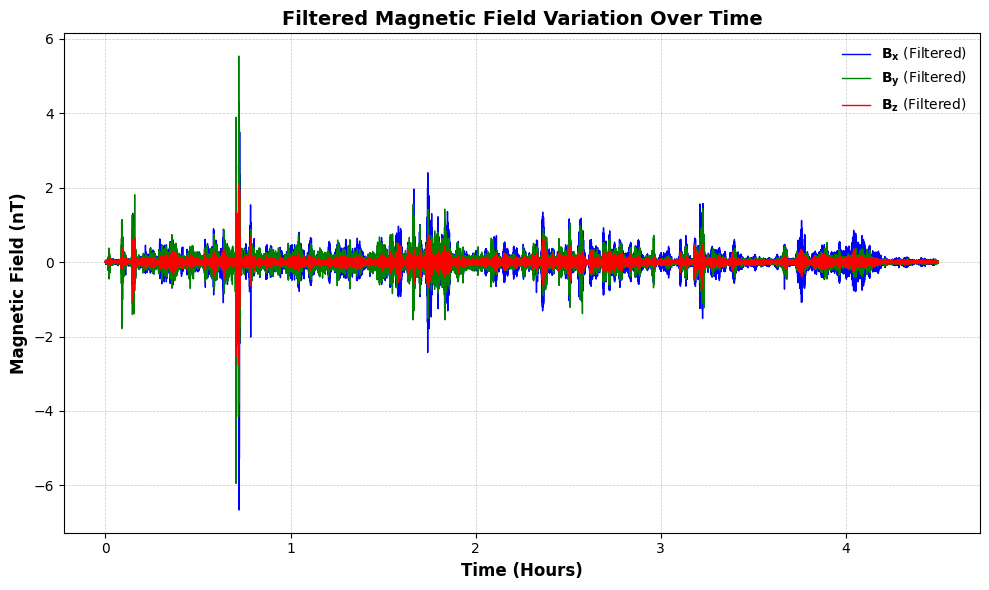

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import butter, filtfilt

# Define the bandpass filter function
def bandpass_filter(data, lowcut, highcut, sampling_freq, order=8):
    nyquist = 0.5 * sampling_freq
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# Filter data for the desired time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# Extract magnetic field and time values for all three components
b_x_filtered = filtered_df['b_x'].values
b_y_filtered = filtered_df['b_y'].values
b_z_filtered = filtered_df['b_z'].values
time_filtered = filtered_df['datetime']

# Convert time to numeric values for easier plotting
time_numeric = (time_filtered - time_filtered.iloc[0]).dt.total_seconds() / 3600  # Convert to hours

# Sampling frequency
time_diff = np.diff(time_filtered).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
sampling_freq = 1 / np.mean(time_diff)  # Hz

# Define the bandpass filter frequency range
lowcut = 0.05  # Low frequency (50 mHz)
highcut = 5    # High frequency (Hz)

# Apply bandpass filter to each magnetic field component
b_x_filtered_signal = bandpass_filter(b_x_filtered, lowcut, highcut, sampling_freq)
b_y_filtered_signal = bandpass_filter(b_y_filtered, lowcut, highcut, sampling_freq)
b_z_filtered_signal = bandpass_filter(b_z_filtered, lowcut, highcut, sampling_freq)

# Plot Filtered Magnetic Field Variation Over Time
plt.figure(figsize=(10, 6))

plt.plot(time_numeric, b_x_filtered_signal, color='blue', linewidth=1, label=r'$\mathbf{B_x}$ (Filtered)')
plt.plot(time_numeric, b_y_filtered_signal, color='green', linewidth=1, label=r'$\mathbf{B_y}$ (Filtered)')
plt.plot(time_numeric, b_z_filtered_signal, color='red', linewidth=1, label=r'$\mathbf{B_z}$ (Filtered)')

plt.xlabel('Time (Hours)', fontsize=12, fontweight='bold')
plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
plt.title('Filtered Magnetic Field Variation Over Time', fontsize=14, fontweight='bold')

plt.legend(frameon=False, fontsize=10)
plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()
plt.savefig('/home/draksha/Downloads/filtered_magnetic_field_time_series.png', dpi=300)
plt.show()


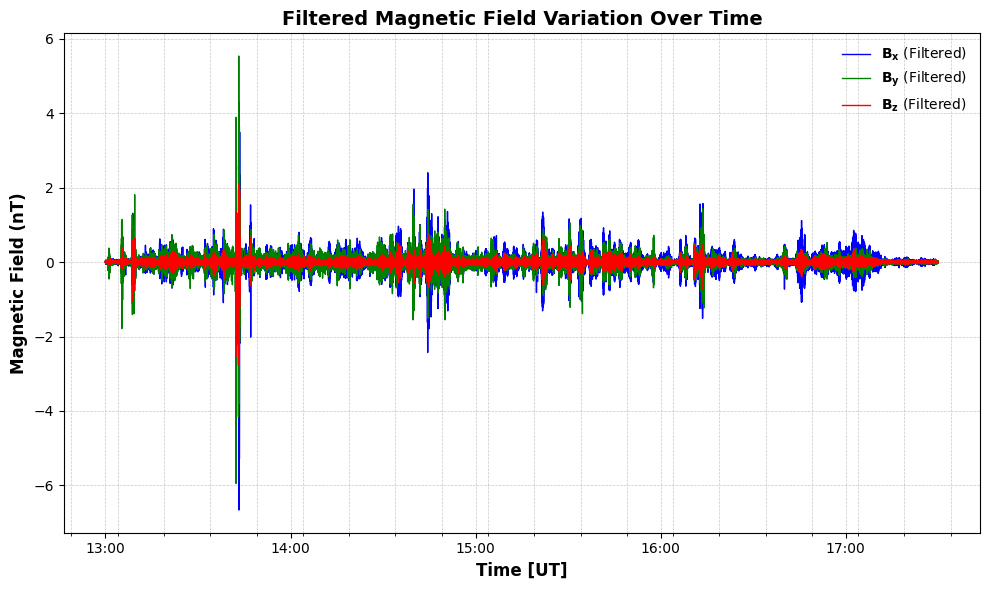

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import butter, filtfilt
import matplotlib.dates as mdates

# Define the bandpass filter function
def bandpass_filter(data, lowcut, highcut, sampling_freq, order=8):
    nyquist = 0.5 * sampling_freq
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# Define time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')

# Filter data for the desired time range
filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# Extract magnetic field components and time values
b_x_filtered = filtered_df['b_x'].values
b_y_filtered = filtered_df['b_y'].values
b_z_filtered = filtered_df['b_z'].values
time_filtered = filtered_df['datetime']

# Sampling frequency calculation
time_diff = np.diff(time_filtered).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
sampling_freq = 1 / np.mean(time_diff)  # Hz

# Define the bandpass filter frequency range
lowcut = 0.05  # Low frequency (50 mHz)
highcut = 5    # High frequency (Hz)

# Apply bandpass filter to each magnetic field component
b_x_filtered_signal = bandpass_filter(b_x_filtered, lowcut, highcut, sampling_freq)
b_y_filtered_signal = bandpass_filter(b_y_filtered, lowcut, highcut, sampling_freq)
b_z_filtered_signal = bandpass_filter(b_z_filtered, lowcut, highcut, sampling_freq)

# Plot Filtered Magnetic Field Variation Over Time
plt.figure(figsize=(10, 6))

plt.plot(time_filtered, b_x_filtered_signal, color='blue', linewidth=1, label=r'$\mathbf{B_x}$ (Filtered)')
plt.plot(time_filtered, b_y_filtered_signal, color='green', linewidth=1, label=r'$\mathbf{B_y}$ (Filtered)')
plt.plot(time_filtered, b_z_filtered_signal, color='red', linewidth=1, label=r'$\mathbf{B_z}$ (Filtered)')

# Format time axis as HH:MM
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=1))  # Major ticks every hour
plt.gca().xaxis.set_minor_locator(mdates.MinuteLocator(interval=15))  # Minor ticks every 15 min

plt.xlabel('Time [UT]', fontsize=12, fontweight='bold')
plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
plt.title('Filtered Magnetic Field Variation Over Time', fontsize=14, fontweight='bold')

plt.legend(frameon=False, fontsize=10)
plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)

plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.savefig('/home/draksha/Downloads/filtered_magnetic_field_time_series.png', dpi=300)
plt.show()


## Line Fitting

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import butter, filtfilt
import matplotlib.dates as mdates

# Define the bandpass filter function
def bandpass_filter(data, lowcut, highcut, sampling_freq, order=8):
    nyquist = 0.5 * sampling_freq
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# Define time range
start_time = pd.Timestamp('2015-10-28 16:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')

# Filter data for the desired time range
filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# Check if the DataFrame is empty
if filtered_df.empty:
    raise ValueError("Error: No data available in the selected time range!")

# Extract magnetic field components and time values
b_x_filtered = filtered_df['b_x'].values
b_y_filtered = filtered_df['b_y'].values
b_z_filtered = filtered_df['b_z'].values
time_filtered = filtered_df['datetime']

# Check if there are at least two timestamps to compute sampling frequency
if len(time_filtered) < 2:
    raise ValueError("Error: Not enough data points in the selected time range!")

# Compute sampling frequency
time_diff = np.diff(time_filtered).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
sampling_freq = 1 / np.mean(time_diff)  # Hz

# Define the bandpass filter frequency range
lowcut = 0.05  # Low frequency (50 mHz)
highcut = 5    # High frequency (Hz)

# Apply bandpass filter to each magnetic field component
b_x_filtered_signal = bandpass_filter(b_x_filtered, lowcut, highcut, sampling_freq)
b_y_filtered_signal = bandpass_filter(b_y_filtered, lowcut, highcut, sampling_freq)
b_z_filtered_signal = bandpass_filter(b_z_filtered, lowcut, highcut, sampling_freq)

# Plot Filtered Magnetic Field Variation Over Time
plt.figure(figsize=(10, 6))

plt.plot(time_filtered, b_x_filtered_signal, color='blue', linewidth=1, label=r'$\mathbf{B_x}$ (Filtered)')
plt.plot(time_filtered, b_y_filtered_signal, color='green', linewidth=1, label=r'$\mathbf{B_y}$ (Filtered)')
plt.plot(time_filtered, b_z_filtered_signal, color='red', linewidth=1, label=r'$\mathbf{B_z}$ (Filtered)')

# Format time axis as HH:MM
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=1))  # Major ticks every hour
plt.gca().xaxis.set_minor_locator(mdates.MinuteLocator(interval=15))  # Minor ticks every 15 min

plt.xlabel('Time [UT]', fontsize=12, fontweight='bold')
plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
plt.title('Filtered Magnetic Field Variation Over Time', fontsize=14, fontweight='bold')

plt.legend(frameon=False, fontsize=10)
plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)

plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.savefig('/home/draksha/Downloads/filtered_magnetic_field_time_series.png', dpi=300)
plt.show()


ValueError: Digital filter critical frequencies must be 0 < Wn < 1

In [ ]:
# # Filter data for the range 10^-3 to 10^-1 Hz
# range_mask = (positive_freqs >= 1e-2) & (positive_freqs <= 1e-1)
# freqs_in_range = positive_freqs[range_mask]
# power_b_x_in_range = positive_power_b_x[range_mask]

# # Log-transform the data
# ln_freqs = np.log(freqs_in_range)
# ln_power = np.log(power_b_x_in_range)

# # Perform linear regression
# coefficients = np.polyfit(ln_freqs, ln_power, 1)  # Fit ln(P) = m * ln(f) + c
# slope = coefficients[0]  # Slope (m)
# intercept = coefficients[1]  # Intercept (c)

# # Print the fitted equation
# print(f"Fitted line equation (log-log): ln(P) = {slope:.3f} * ln(f) + {intercept:.3f}")

# # Generate the fitted line in the original scale
# fitted_power = np.exp(intercept) * freqs_in_range**slope

# # Plot Power Spectrum with the fitted line
# plt.figure(figsize=(10, 5))
# plt.loglog(positive_freqs, positive_power_b_x, color='blue', label='B_x Power Spectrum')
# plt.loglog(freqs_in_range, fitted_power, color='red', linestyle='--', linewidth=2, label=f'Fit: P ∝ f^{slope:.2f}')

# # Add labels and title
# plt.xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
# plt.ylabel('Power (nT^2/Hz)', fontsize=12, fontweight='bold')
# plt.title('Power Spectrum with Line Fitting (10^-3 to 10^-1 Hz)', fontsize=14, fontweight='bold')
# plt.xlim(1e-2, 1e-1)  # Focus on the fitting range
# plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)
# plt.legend(frameon=False, fontsize=10)

# # Show the plot
# plt.tight_layout()
# plt.show()


## Spectrogram of Bx,By,Bz (using spectrogram function)

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# # Function to compute spectrogram
# def compute_spectrogram(b_field, sampling_freq, nperseg=1024):
#     f, t, Sxx = spectrogram(b_field, fs=sampling_freq, nperseg=nperseg)
#     return f, t, Sxx

# # Compute spectrogram for all three components
# f_b_x, t_b_x, Sxx_b_x = compute_spectrogram(b_x_filtered, sampling_freq)
# f_b_y, t_b_y, Sxx_b_y = compute_spectrogram(b_y_filtered, sampling_freq)
# f_b_z, t_b_z, Sxx_b_z = compute_spectrogram(b_z_filtered, sampling_freq)

# # Plot Spectrograms for all three components
# plt.figure(figsize=(15, 8))

# # Plot B_x spectrogram
# plt.subplot(3, 1, 1)
# pcm_x = plt.pcolormesh(
#     t_b_x, f_b_x, Sxx_b_x, 
#     shading='auto', cmap='jet', 
#     norm=LogNorm(vmin=1e-8, vmax=1e-1) 
# )
# plt.yscale('log')  # Log scale for frequency
# plt.ylim(0.1, 1.5)  # Limit frequency range
# plt.title('Spectrogram of B_x', fontsize=14, fontweight='bold')
# plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
# cbar_x = plt.colorbar(pcm_x, label='Power ((nT^2/Hz)', pad=0.02)

# # Plot B_y spectrogram
# plt.subplot(3, 1, 2)
# pcm_y = plt.pcolormesh(
#     t_b_y, f_b_y, Sxx_b_y, 
#     shading='auto', cmap='jet', 
#     norm=LogNorm(vmin=1e-6, vmax=1e-1)
# )
# plt.yscale('log')  # Log scale for frequency
# plt.ylim(0.1, 1.5)  # Limit frequency range
# plt.title('Spectrogram of B_y', fontsize=14, fontweight='bold')
# plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
# cbar_y = plt.colorbar(pcm_y, label='Power ((nT^2/Hz)', pad=0.02)

# # Plot B_z spectrogram
# plt.subplot(3, 1, 3)
# pcm_z = plt.pcolormesh(
#     t_b_z, f_b_z, Sxx_b_z, 
#     shading='auto', cmap='jet', 
#     norm=LogNorm(vmin=1e-5, vmax=1e1)
# )
# plt.yscale('log')  # Log scale for frequency
# plt.ylim(0.1, 1.5)  # Limit frequency range
# plt.title('Spectrogram of B_z', fontsize=14, fontweight='bold')
# plt.xlabel('Time (s)', fontsize=12, fontweight='bold')
# plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
# cbar_z = plt.colorbar(pcm_z, label='Power (nT^2/Hz)', pad=0.02)

# # Adjust layout and show the plot
# plt.tight_layout()
# plt.show()


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# import pandas as pd

# Function to compute spectrogram with common time axis
def compute_spectrogram(b_field, sampling_freq, nperseg=1024):
    f, t, Sxx = spectrogram(b_field, fs=sampling_freq, nperseg=nperseg)
    return f, t, Sxx

# Compute spectrogram for B_x first to get common time `t`
f_common, t_common, Sxx_b_x = compute_spectrogram(b_x_filtered, sampling_freq)
_, _, Sxx_b_y = compute_spectrogram(b_y_filtered, sampling_freq)
_, _, Sxx_b_z = compute_spectrogram(b_z_filtered, sampling_freq)

# Convert `t_common` to actual time format
time_start = filtered_df['datetime'].iloc[0]
time_axis = [time_start + pd.Timedelta(seconds=t) for t in t_common]

# Plot Spectrograms with common time axis
fig, axes = plt.subplots(3, 1, figsize=(15, 8), sharex=True)

# Plot B_x spectrogram
pcm_x = axes[0].pcolormesh(
    time_axis, f_common, Sxx_b_x, 
    shading='auto', cmap='jet', 
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
axes[0].set_yscale('log')
axes[0].set_ylim(0.1, 1.5)
axes[0].set_title('Spectrogram of B_x', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
fig.colorbar(pcm_x, ax=axes[0], label='Power (nT^2/Hz)', pad=0.02)

# Plot B_y spectrogram
pcm_y = axes[1].pcolormesh(
    time_axis, f_common, Sxx_b_y, 
    shading='auto', cmap='jet', 
    norm=LogNorm(vmin=1e-6, vmax=1e-1)
)
axes[1].set_yscale('log')
axes[1].set_ylim(0.1, 1.5)
axes[1].set_title('Spectrogram of B_y', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
fig.colorbar(pcm_y, ax=axes[1], label='Power (nT^2/Hz)', pad=0.02)

# Plot B_z spectrogram
pcm_z = axes[2].pcolormesh(
    time_axis, f_common, Sxx_b_z, 
    shading='auto', cmap='jet', 
    norm=LogNorm(vmin=1e-5, vmax=1e1)
)
axes[2].set_yscale('log')
axes[2].set_ylim(0.1, 1.5)
axes[2].set_title('Spectrogram of B_z', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Time (HH:MM)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
fig.colorbar(pcm_z, ax=axes[2], label='Power (nT^2/Hz)', pad=0.02)

# Format time axis to HH:MM
axes[2].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%H:%M'))

# Adjust layout and show the plot
plt.tight_layout()
plt.savefig('/home/draksha/Downloads/spectrogram.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# import pandas as pd
# from spacepy import pycdf
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.colors import LogNorm
# from scipy.signal import spectrogram

# # Load the CDF file
# cdf_path = '/home/draksha/pydata/mms1/fgm/srvy/l2/2015/10/mms1_fgm_srvy_l2_20151028_v4.18.0.cdf'
# cdf = pycdf.CDF(cdf_path)

# # Extract magnetic field data and timestamps
# datetime = pd.to_datetime(cdf['Epoch'][:])
# b_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
# b_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
# b_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]
# b_t = np.linalg.norm([b_x, b_y, b_z], axis=0)

# # Combine into a DataFrame
# df = pd.DataFrame({
#     'datetime': datetime,
#     'b_x': b_x,
#     'b_y': b_y,
#     'b_z': b_z,
#     'b_t': b_t
# })

# # Drop any NaN values
# df.dropna(inplace=True)

# Filter data within the desired time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
df_filtered = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# Convert datetime to seconds relative to the start of the filtered range
time_in_seconds = (df_filtered['datetime'] - df_filtered['datetime'].iloc[0]).dt.total_seconds()

# Calculate sampling frequency
sampling_freq = 1 / np.mean(np.diff(time_in_seconds))

# Function to compute spectrogram
def compute_spectrogram(b_field, sampling_freq, nperseg=1024):
    f, t, Sxx = spectrogram(b_field, fs=sampling_freq, nperseg=nperseg)
    return f, t, Sxx

# Compute spectrograms for all components
f_b_x, t_b_x, Sxx_b_x = compute_spectrogram(df_filtered['b_x'].values, sampling_freq)
f_b_y, t_b_y, Sxx_b_y = compute_spectrogram(df_filtered['b_y'].values, sampling_freq)
f_b_z, t_b_z, Sxx_b_z = compute_spectrogram(df_filtered['b_z'].values, sampling_freq)
f_b_t, t_b_t, Sxx_b_t = compute_spectrogram(df_filtered['b_t'].values, sampling_freq)

# Convert spectrogram times to minutes
t_b_x_minutes = (t_b_x + time_in_seconds.iloc[0]) / 60
t_b_y_minutes = (t_b_y + time_in_seconds.iloc[0]) / 60
t_b_z_minutes = (t_b_z + time_in_seconds.iloc[0]) / 60
t_b_t_minutes = (t_b_t + time_in_seconds.iloc[0]) / 60

# # Plot spectrograms for all components
# plt.figure(figsize=(15, 12))

# # Spectrogram for B_x
# plt.subplot(4, 1, 1)
# pcm_x = plt.pcolormesh(
#     t_b_x_minutes, f_b_x, Sxx_b_x,
#     shading='auto', cmap='jet',
#     norm=LogNorm(vmin=1e-8, vmax=1e-1)
# )
# plt.yscale('log')
# plt.ylim(0.1, 1.5)
# plt.colorbar(pcm_x, label='Power (Log Scale)', pad=0.02)
# plt.title('Spectrogram of B_x', fontsize=14, fontweight='bold')
# plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')

# # Spectrogram for B_y
# plt.subplot(4, 1, 2)
# pcm_y = plt.pcolormesh(
#     t_b_y_minutes, f_b_y, Sxx_b_y,
#     shading='auto', cmap='jet',
#     norm=LogNorm(vmin=1e-8, vmax=1e-1)
# )
# plt.yscale('log')
# plt.ylim(0.1, 1.5)
# plt.colorbar(pcm_y, label='Power (Log Scale)', pad=0.02)
# plt.title('Spectrogram of B_y', fontsize=14, fontweight='bold')
# plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')

# # Spectrogram for B_z
# plt.subplot(4, 1, 3)
# pcm_z = plt.pcolormesh(
#     t_b_z_minutes, f_b_z, Sxx_b_z,
#     shading='auto', cmap='jet',
#     norm=LogNorm(vmin=1e-8, vmax=1e-1)
# )
# plt.yscale('log')
# plt.ylim(0.1, 1.5)
# plt.colorbar(pcm_z, label='Power (Log Scale)', pad=0.02)
# plt.title('Spectrogram of B_z', fontsize=14, fontweight='bold')
# plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')

# # Spectrogram for B_t (optional)
# plt.subplot(4, 1, 4)
# pcm_t = plt.pcolormesh(
#     t_b_t_minutes, f_b_t, Sxx_b_t,
#     shading='auto', cmap='jet',
#     norm=LogNorm(vmin=1e-8, vmax=1e-1)
# )
# plt.yscale('log')
# plt.ylim(0.1, 1.5)
# plt.colorbar(pcm_t, label='Power (Log Scale)', pad=0.02)
# plt.title('Spectrogram of B_t', fontsize=14, fontweight='bold')
# plt.xlabel('Time (minutes) since start of CDF', fontsize=12, fontweight='bold')
# plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')

# # Adjust layout
# plt.tight_layout()
# plt.show()


In [ ]:
filtered_df

In [ ]:
import matplotlib.dates as mdates

# Update spectrogram time arrays to be datetime values for formatting
t_b_x_datetime = pd.to_datetime(filtered_df['datetime'].iloc[0]) + pd.to_timedelta(t_b_x, unit='s')
t_b_y_datetime = pd.to_datetime(filtered_df['datetime'].iloc[0]) + pd.to_timedelta(t_b_y, unit='s')
t_b_z_datetime = pd.to_datetime(filtered_df['datetime'].iloc[0]) + pd.to_timedelta(t_b_z, unit='s')
t_b_t_datetime = pd.to_datetime(filtered_df['datetime'].iloc[0]) + pd.to_timedelta(t_b_t, unit='s')

# Plot spectrograms for all components
plt.figure(figsize=(12, 8))

# Spectrogram for B_x
plt.subplot(3, 1, 1)
pcm_x = plt.pcolormesh(
    t_b_x_datetime, f_b_x, Sxx_b_x,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
plt.yscale('log')
plt.ylim(0.1, 1.5)
plt.colorbar(pcm_x, label='Power (nT^2/Hz)', pad=0.02)
plt.title('Spectrogram of B_x', fontsize=14, fontweight='bold')
plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

# Spectrogram for B_y
plt.subplot(3, 1, 2)
pcm_y = plt.pcolormesh(
    t_b_y_datetime, f_b_y, Sxx_b_y,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
plt.yscale('log')
plt.ylim(0.1, 1.5)
plt.colorbar(pcm_y, label='Power (nT^2/Hz)', pad=0.02)
plt.title('Spectrogram of B_y', fontsize=14, fontweight='bold')
plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

# Spectrogram for B_z
plt.subplot(3, 1, 3)
pcm_z = plt.pcolormesh(
    t_b_z_datetime, f_b_z, Sxx_b_z,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
plt.yscale('log')
plt.ylim(0.1, 1.5)
plt.colorbar(pcm_z, label='Power (nT^2/Hz)', pad=0.02)
plt.title('Spectrogram of B_z', fontsize=14, fontweight='bold')
plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

# # Spectrogram for B_t
# plt.subplot(4, 1, 4)
# pcm_t = plt.pcolormesh(
#     t_b_t_datetime, f_b_t, Sxx_b_t,
#     shading='auto', cmap='jet',
#     norm=LogNorm(vmin=1e-8, vmax=1e-1)
# )
# plt.yscale('log')
# plt.ylim(0.1, 1.5)
# plt.colorbar(pcm_t, label='Power (Log Scale)', pad=0.02)
# plt.title('Spectrogram of B_t', fontsize=14, fontweight='bold')
# plt.xlabel('Time (HH:MM)', fontsize=12, fontweight='bold')
# plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
# plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

# Adjust layout
plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import pandas as pd

# Update spectrogram time arrays to be datetime values for formatting
t_b_x_datetime = pd.to_datetime(filtered_df['datetime'].iloc[0]) + pd.to_timedelta(t_b_x, unit='s')
t_b_y_datetime = pd.to_datetime(filtered_df['datetime'].iloc[0]) + pd.to_timedelta(t_b_y, unit='s')
t_b_z_datetime = pd.to_datetime(filtered_df['datetime'].iloc[0]) + pd.to_timedelta(t_b_z, unit='s')

# Create figure and subplots with a shared x-axis
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# Spectrogram for B_x
pcm_x = axes[0].pcolormesh(
    t_b_x_datetime, f_b_x, Sxx_b_x,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
axes[0].set_yscale('log')
axes[0].set_ylim(0.1, 1.5)
fig.colorbar(pcm_x, ax=axes[0], label='Power (nT²/Hz)', pad=0.02)
axes[0].set_title('Spectrogram of B_x', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')

# Spectrogram for B_y
pcm_y = axes[1].pcolormesh(
    t_b_y_datetime, f_b_y, Sxx_b_y,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
axes[1].set_yscale('log')
axes[1].set_ylim(0.1, 1.5)
fig.colorbar(pcm_y, ax=axes[1], label='Power (nT²/Hz)', pad=0.02)
axes[1].set_title('Spectrogram of B_y', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')

# Spectrogram for B_z
pcm_z = axes[2].pcolormesh(
    t_b_z_datetime, f_b_z, Sxx_b_z,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
axes[2].set_yscale('log')
axes[2].set_ylim(0.1, 1.5)
fig.colorbar(pcm_z, ax=axes[2], label='Power (nT²/Hz)', pad=0.02)
axes[2].set_title('Spectrogram of B_z', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')

# Set common x-axis format
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # Format time in HH:MM
axes[-1].set_xlabel('Time [UT]', fontsize=12, fontweight='bold')  # Add x-label only to last subplot

# Rotate x-ticks for better readability
plt.xticks(rotation=0, fontsize=10)

# Adjust layout
plt.tight_layout()
plt.savefig('/home/draksha/Downloads/Changed_spectrogram.png')
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import pandas as pd

# Update spectrogram time arrays to be datetime values for formatting
t_b_x_datetime = pd.to_datetime(filtered_df['datetime'].iloc[0]) + pd.to_timedelta(t_b_x, unit='s')
t_b_y_datetime = pd.to_datetime(filtered_df['datetime'].iloc[0]) + pd.to_timedelta(t_b_y, unit='s')
t_b_z_datetime = pd.to_datetime(filtered_df['datetime'].iloc[0]) + pd.to_timedelta(t_b_z, unit='s')

# Create figure and subplots with a shared x-axis
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# Define horizontal line properties
hline_y_values = [0.6, 0.28]  # Frequencies where horizontal lines should be drawn
hline_style = {'color': 'white', 'linestyle': '--', 'linewidth': 1.5}  # White dashed lines

# Spectrogram for B_x
pcm_x = axes[0].pcolormesh(
    t_b_x_datetime, f_b_x, Sxx_b_x,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
axes[0].set_yscale('log')
axes[0].set_ylim(0.1, 1.5)
fig.colorbar(pcm_x, ax=axes[0], label='Power (nT²/Hz)', pad=0.02)
axes[0].set_title('Spectrogram of B_x', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
for y_val in hline_y_values:
    axes[0].axhline(y=y_val, **hline_style)  # Add horizontal lines

# Spectrogram for B_y
pcm_y = axes[1].pcolormesh(
    t_b_y_datetime, f_b_y, Sxx_b_y,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
axes[1].set_yscale('log')
axes[1].set_ylim(0.1, 1.5)
fig.colorbar(pcm_y, ax=axes[1], label='Power (nT²/Hz)', pad=0.02)
axes[1].set_title('Spectrogram of B_y', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
for y_val in hline_y_values:
    axes[1].axhline(y=y_val, **hline_style)  # Add horizontal lines

# Spectrogram for B_z
pcm_z = axes[2].pcolormesh(
    t_b_z_datetime, f_b_z, Sxx_b_z,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
axes[2].set_yscale('log')
axes[2].set_ylim(0.1, 1.5)
fig.colorbar(pcm_z, ax=axes[2], label='Power (nT²/Hz)', pad=0.02)
axes[2].set_title('Spectrogram of B_z', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
for y_val in hline_y_values:
    axes[2].axhline(y=y_val, **hline_style)  # Add horizontal lines

# Set common x-axis format
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))  # Format time in HH:MM
axes[-1].set_xlabel('Time [UT]', fontsize=12, fontweight='bold')  # Add x-label only to last subplot

# Rotate x-ticks for better readability
plt.xticks(rotation=45, fontsize=10)

# Adjust layout
plt.tight_layout()
plt.show()


## Stacked Plots 

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# import pandas as pd
# from scipy.signal import butter, filtfilt, spectrogram

# # Define the bandpass filter function
# def bandpass_filter(data, lowcut, highcut, sampling_freq, order=4):
#     nyquist = 0.5 * sampling_freq
#     low = lowcut / nyquist
#     high = highcut / nyquist
#     b, a = butter(order, [low, high], btype='band')
#     return filtfilt(b, a, data)

# # Filter data for the desired time range
# start_time = pd.Timestamp('2015-10-28 13:00:00')
# end_time = pd.Timestamp('2015-10-28 17:30:00')
# filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# # Extract magnetic field and time values for all three components
# b_x_filtered = filtered_df['b_x'].values
# b_y_filtered = filtered_df['b_y'].values
# b_z_filtered = filtered_df['b_z'].values
# time_filtered = filtered_df['datetime']

# # Sampling frequency
# time_diff = np.diff(time_filtered).astype('timedelta64[ns]').astype(float) / 1e9  # Convert to seconds
# sampling_freq = 1 / np.mean(time_diff)  # Hz

# # Define the bandpass filter frequency range
# lowcut = 0.05  # Low frequency (Hz)
# highcut = 5 # High frequency (Hz)

# # Apply bandpass filter to each magnetic field component
# b_x_filtered_filtered = bandpass_filter(b_x_filtered, lowcut, highcut, sampling_freq)
# b_y_filtered_filtered = bandpass_filter(b_y_filtered, lowcut, highcut, sampling_freq)
# b_z_filtered_filtered = bandpass_filter(b_z_filtered, lowcut, highcut, sampling_freq)

# # Function to compute power spectral density
# def compute_psd(b_field):
#     n = len(b_field)  # Number of samples
#     fft_result = np.fft.fft(b_field)  # Compute FFT
#     fft_freqs = np.fft.fftfreq(n, d=1/sampling_freq)  # Compute FFT frequencies
#     psd = np.abs(fft_result)**2  # Power Spectral Density (no dB scaling)
#     return fft_freqs, psd

# # Compute PSD for all three components
# fft_freqs, psd_b_x = compute_psd(b_x_filtered_filtered)
# _, psd_b_y = compute_psd(b_y_filtered_filtered)
# _, psd_b_z = compute_psd(b_z_filtered_filtered)

# # Function to compute spectrogram
# def compute_spectrogram(b_field, sampling_freq, nperseg=1024):
#     f, t, Sxx = spectrogram(b_field, fs=sampling_freq, nperseg=nperseg)
#     return f, t, Sxx

# # Compute spectrogram for all three components
# f_b_x, t_b_x, Sxx_b_x = compute_spectrogram(b_x_filtered_filtered, sampling_freq)
# f_b_y, t_b_y, Sxx_b_y = compute_spectrogram(b_y_filtered_filtered, sampling_freq)
# f_b_z, t_b_z, Sxx_b_z = compute_spectrogram(b_z_filtered_filtered, sampling_freq)

# # Plot stacked plots
# plt.figure(figsize=(17, 15))

# # Plot Magnetic Field: B_X
# plt.subplot(6, 1, 1)
# plt.plot(df['datetime'], b_x, label='B_x', color='cyan')
# plt.plot(df['datetime'], b_y, label='B_y', color='magenta')
# plt.plot(df['datetime'], b_z, label='B_z', color='green')
# plt.plot(df['datetime'], b_t, label='B_T', color='black')
# # Set y-axis limits
# plt.ylim(-10, 60)

# # Set x-axis limits to focus on the desired time range
# # Convert the datetime range to pandas Timestamp
# start_time = pd.Timestamp('2015-10-28 13:00:00')
# end_time = pd.Timestamp('2015-10-28 17:30:00')
# plt.xlim(start_time, end_time)

# # Add labels and title
# plt.xlabel('Datetime', fontsize=12, fontweight='bold')
# plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
# plt.title('Magnetic Field vs Time', fontsize=14, fontweight='bold')

# # Rotate x-axis labels for better readability
# plt.xticks(rotation=45, fontsize=10)
# plt.yticks(fontsize=10)

# # Add grid and legend
# plt.grid(linestyle='--', alpha=0.5)
# plt.legend(frameon=False, fontsize=10)



# # Plot Power Spectrum for all three components
# plt.subplot(6, 1, 2)
# plt.loglog(positive_freqs, positive_power_b_x, color='blue', label='B_x')
# plt.loglog(positive_freqs, positive_power_b_y, color='green', label='B_y')
# plt.loglog(positive_freqs, positive_power_b_z, color='red', label='B_z')
# # Add vertical lines at 0.5 Hz and 0.8 Hz
# plt.axvline(x=0.25, color='purple', linestyle='--', linewidth=1, label='Peak at 0.285 Hz')
# plt.axvline(x=0.65, color='orange', linestyle='--', linewidth=1, label='Peak at 0.65 Hz')


# # Add labels and title
# plt.xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
# plt.ylabel('Power (nT^2)', fontsize=12, fontweight='bold')
# plt.title('Power Spectrum of Magnetic Field Components', fontsize=14, fontweight='bold')

# # Add grid and legend
# plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)
# plt.legend(frameon=False, fontsize=10)


# # Plot Spectrogram: B_X
# plt.subplot(6, 1, 3)
# plt.loglog(positive_freqs, positive_power_b_x, color='blue', label='B_x')
# plt.loglog(positive_freqs, positive_power_b_y, color='green', label='B_y')
# plt.loglog(positive_freqs, positive_power_b_z, color='red', label='B_z')

# # Add vertical lines at 0.5 Hz and 0.8 Hz
# plt.axvline(x=0.25, color='purple', linestyle='--', linewidth=1, label='Peak at 0.285 Hz')
# plt.axvline(x=0.65, color='orange', linestyle='--', linewidth=1, label='Peak at 0.65 Hz')


# # Add labels and title
# plt.xlabel('Frequency (Hz)', fontsize=12, fontweight='bold')
# plt.ylabel('Power (nT^2)', fontsize=12, fontweight='bold')
# plt.title('Power Spectrum of Filtered Magnetic Field Components', fontsize=14, fontweight='bold')

# # Add grid and legend
# plt.grid(which='both', linestyle='--', linewidth=0.5, alpha=0.7)
# plt.legend(frameon=False, fontsize=10)


# # Plot B_GSE0 spectrogram
# plt.subplot(6, 1, 4)
# plt.pcolormesh(t_b_x, f_b_x, 10 * np.log10(Sxx_b_x), shading='auto', cmap='viridis')
# plt.title('Spectrogram of B_x', fontsize=14, fontweight='bold')
# plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
# plt.colorbar(label='Power ')

# # Plot B_GSE1 spectrogram
# plt.subplot(6, 1, 5)
# plt.pcolormesh(t_b_y, f_b_y, 10 * np.log10(Sxx_b_y), shading='auto', cmap='viridis')
# plt.title('Spectrogram of B_y', fontsize=14, fontweight='bold')
# plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
# plt.colorbar(label='Power')

# # Plot B_GSE2 spectrogram
# plt.subplot(6, 1, 6)
# plt.pcolormesh(t_b_z, f_b_z, 10 * np.log10(Sxx_b_z), shading='auto', cmap='viridis')
# plt.title('Spectrogram of B_z', fontsize=14, fontweight='bold')
# plt.xlabel('Time (s)', fontsize=12, fontweight='bold')
# plt.ylabel('Frequency (Hz)', fontsize=12, fontweight='bold')
# plt.colorbar(label='Power ')


# # Adjust layout and show the plot
# plt.tight_layout()
# plt.show()


In [ ]:
# from scipy.signal import butter, filtfilt
# from numpy.linalg import eig

# # Step 2: Define bandpass filter
# def bandpass_filter(data, lowcut, highcut, fs, order=4):
#     nyquist = 0.5 * fs
#     low = lowcut / nyquist
#     high = highcut / nyquist
#     b, a = butter(order, [low, high], btype='band')
#     return filtfilt(b, a, data)

# # Define wave frequency range (adjust if needed)
# low_freq = 0.1  # Hz
# high_freq = 1.5  # Hz

# # Apply bandpass filter to each magnetic field component
# b_x_filtered = bandpass_filter(df_filtered['b_x'].values, low_freq, high_freq, sampling_freq)
# b_y_filtered = bandpass_filter(df_filtered['b_y'].values, low_freq, high_freq, sampling_freq)
# b_z_filtered = bandpass_filter(df_filtered['b_z'].values, low_freq, high_freq, sampling_freq)

# # Step 3: Extract 100 cycles
# dominant_freq = 0.5  # Choose based on spectrogram analysis
# num_cycles = 100
# T_cycle = 1 / dominant_freq  # Period of one cycle
# T_total = num_cycles * T_cycle  # Total duration needed
# t_start = time_in_seconds.iloc[0]
# t_end = t_start + T_total

# df_segment = df_filtered[(time_in_seconds >= t_start) & (time_in_seconds <= t_end)]

# # Extract the filtered wave segment
# B_wave = np.vstack([
#     b_x_filtered[:len(df_segment)],
#     b_y_filtered[:len(df_segment)],
#     b_z_filtered[:len(df_segment)]
# ]).T

# # Step 4: Compute Planarity using Minimum Variance Analysis (MVA)
# cov_matrix = np.cov(B_wave, rowvar=False)  # Covariance matrix
# eigenvalues, eigenvectors = eig(cov_matrix)  # Eigen decomposition
# sorted_eigenvalues = np.sort(eigenvalues)  # Sort in ascending order

# # Compute planarity: λ2 / λ3
# planarity = 1 - np.sqrt( sorted_eigenvalues[0] / sorted_eigenvalues[2])

# print(f"Planarity of the wave: {planarity:.4f}")


In [ ]:
filtered_df

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# import pandas as pd
# from scipy.signal import butter, filtfilt, spectrogram
from matplotlib.gridspec import GridSpec
# from matplotlib.colors import LogNorm

# Function to compute FFT and Power Spectrum
def compute_fft(b_field, sampling_freq):
    n = len(b_field)  
    fft_result = np.fft.fft(b_field) / n  
    fft_freqs = np.fft.fftfreq(n, d=1/sampling_freq)  
    fft_power = (np.abs(fft_result) ** 2) * n  
    return fft_freqs[:n//2], fft_power[:n//2]  # Only positive frequencies

# Bandpass filter function
def bandpass_filter(data, lowcut, highcut, sampling_freq, order=8):
    nyquist = 0.5 * sampling_freq
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# Load and filter data
df = pd.read_csv('magnetic_data.csv', parse_dates=['datetime'])  # Replace with actual file path

# # Define time range
start_time = pd.Timestamp('2015-10-28 13:00:00')
end_time = pd.Timestamp('2015-10-28 17:30:00')
filtered_df = df[(df['datetime'] >= start_time) & (df['datetime'] <= end_time)]

# # # Extract components
b_x, b_y, b_z , b_t= filtered_df['b_x'].values, filtered_df['b_y'].values, filtered_df['b_z'].values, filtered_df['b_t'].values
time_axis = filtered_df['datetime']

# Compute sampling frequency
time_diff = np.diff(time_axis).astype('timedelta64[ns]').astype(float) / 1e9
sampling_freq = 1 / np.median(time_diff)

# Compute FFT power spectrum
freqs, power_b_x = compute_fft(b_x, sampling_freq)
_, power_b_y = compute_fft(b_y, sampling_freq)
_, power_b_z = compute_fft(b_z, sampling_freq)

# Apply bandpass filter
lowcut, highcut = 0.05, 5  # Define filter range (Hz)
b_x_filtered = bandpass_filter(b_x, lowcut, highcut, sampling_freq)
b_y_filtered = bandpass_filter(b_y, lowcut, highcut, sampling_freq)
b_z_filtered = bandpass_filter(b_z, lowcut, highcut, sampling_freq)

# Compute FFT for filtered signals
_, power_b_x_filtered = compute_fft(b_x_filtered, sampling_freq)
_, power_b_y_filtered = compute_fft(b_y_filtered, sampling_freq)
_, power_b_z_filtered = compute_fft(b_z_filtered, sampling_freq)

# Compute spectrograms
def compute_spectrogram(b_field, sampling_freq):
    f, t, Sxx = spectrogram(b_field, fs=sampling_freq, nperseg=1024)
    return f, t, Sxx

f_common, t_common, Sxx_b_x = compute_spectrogram(b_x, sampling_freq)
_, _, Sxx_b_y = compute_spectrogram(b_y, sampling_freq)
_, _, Sxx_b_z = compute_spectrogram(b_z, sampling_freq)

# Convert `t_common` to actual time format
time_spectrogram = [filtered_df['datetime'].iloc[0] + pd.Timedelta(seconds=t) for t in t_common]

# Create figure and GridSpec layout
fig = plt.figure(figsize=(12, 12), layout="constrained")
gs = GridSpec(6, 4, figure=fig)

# Top Row: Magnetic Field Time Series
ax1 = fig.add_subplot(gs[0, :])
# Add labels (a, b, c, d, e, f) below each plot
ax1.text(0.02, -0.35, '(a)', transform=ax1.transAxes, fontsize=12)
ax1.plot(time_axis, b_x, label="B_x", color="cyan")
ax1.plot(time_axis, b_y, label="B_y", color="magenta")
ax1.plot(time_axis, b_z, label="B_z", color="green")
ax1.plot(time_axis, b_t, label='B_T', color='black')
ax1.set_ylabel("Magnetic Field (nT)")
ax1.set_title("Magnetic Field vs Time")
ax1.legend()
ax1.grid()

# Middle Left: Power Spectrum
ax2 = fig.add_subplot(gs[1, :])
ax2.loglog(freqs, power_b_x, color="blue", label="B_x")
ax2.loglog(freqs, power_b_y, color="green", label="B_y")
ax2.loglog(freqs, power_b_z, color="red", label="B_z")
ax2.axvline(x=0.285, color="purple", linestyle="--", linewidth=1, label=r"0.285 Hz (He$^{2+}$)")
ax2.axvline(x=0.65, color="blue", linestyle="--", linewidth=1, label=r"0.65 Hz (H$^+$)")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Power (nT²/Hz)")
ax2.set_title("Power Spectrum")
ax2.legend()
ax2.grid(which="both", linestyle="--", linewidth=0.5)

# Middle Right: Filtered Power Spectrum
ax3 = fig.add_subplot(gs[2, :])
ax3.loglog(freqs, power_b_x_filtered, color="blue", label="B_x (filtered)")
ax3.loglog(freqs, power_b_y_filtered, color="green", label="B_y (filtered)")
ax3.loglog(freqs, power_b_z_filtered, color="red", label="B_z (filtered)")
ax3.set_xlim(0.01,1.5)
ax3.axvline(x=0.285, color="purple", linestyle="--", linewidth=1, label=r"0.285 Hz (He$^{2+}$)")
ax3.axvline(x=0.65, color="blue", linestyle="--", linewidth=1, label=r"0.65 Hz (H$^+$)")
ax3.set_xlabel("Frequency (Hz)")
ax3.set_ylabel("Power (nT²/Hz)")
ax3.set_title("Filtered Power Spectrum")
ax3.legend()
ax3.grid(which="both", linestyle="--", linewidth=0.5)

# Bottom Row: Spectrograms
ax4 = fig.add_subplot(gs[3, :])

pcm_x = ax4.pcolormesh(
    t_b_x_datetime, f_b_x, Sxx_b_x,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
ax4.set_yscale('log')
ax4.set_ylim(0.1, 1.5)
ax4.set_title('Spectrogram of B_x', fontsize=14)
ax4.set_ylabel('Frequency (Hz)', fontsize=12)
fig.colorbar(pcm_x, label='Power (nT^2/Hz)', pad=0.02)
# ax4.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))


# plt.pcolormesh(
#     t_b_y_datetime, f_b_y, Sxx_b_y,
#     shading='auto', cmap='jet',
#     norm=LogNorm(vmin=1e-8, vmax=1e-1)
# pcm_x = ax4.pcolormesh(time_spectrogram, f_common, Sxx_b_x, shading="auto", cmap="jet", norm=LogNorm(vmin=1e-8, vmax=1e-1))
# ax4.set_yscale("log")
# ax4.set_title("Spectrogram of B_x")
# ax4.set_ylabel("Frequency (Hz)")
# fig.colorbar(pcm_x, ax=ax4, label="Power (nT²/Hz)")

ax5 = fig.add_subplot(gs[4, :])
pcm_y = ax5.pcolormesh(
    t_b_y_datetime, f_b_y, Sxx_b_y,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
ax5.set_yscale("log")
ax5.set_ylim(0.1, 1.5)
ax5.set_title('Spectrogram of B_y', fontsize=14)
ax5.set_ylabel('Frequency (Hz)', fontsize=12)
fig.colorbar(pcm_y, ax=ax5, label="Power (nT²/Hz)")

ax6 = fig.add_subplot(gs[5, :])
pcm_z = ax6.pcolormesh(
    t_b_z_datetime, f_b_z, Sxx_b_z,
    shading='auto', cmap='jet',
    norm=LogNorm(vmin=1e-8, vmax=1e-1)
)
ax6.set_yscale("log")
ax6.set_ylim(0.1, 1.5)
ax6.set_title('Spectrogram of B_z', fontsize=14)
ax6.set_ylabel('Frequency (Hz)', fontsize=12)
fig.colorbar(pcm_z, ax=ax6, label="Power (nT²/Hz)")

# Make all text bold
plt.rcParams.update({'font.weight': 'bold'})

# Update labels and titles
ax1.set_ylabel("Magnetic Field (nT)", fontweight="bold")
ax1.set_title("Magnetic Field vs Time", fontweight="bold")
ax1.set_xlabel("Time (UT)", fontweight="bold")

ax2.set_xlabel("Frequency (Hz)", fontweight="bold")
ax2.set_ylabel("Power (nT²/Hz)", fontweight="bold")
ax2.set_title("Power Spectrum", fontweight="bold")

ax3.set_xlabel("Frequency (Hz)", fontweight="bold")
ax3.set_ylabel("Power (nT²/Hz)", fontweight="bold")
ax3.set_title("Filtered Power Spectrum", fontweight="bold")

ax4.set_title("Spectrogram of B_x", fontweight="bold")
ax4.set_ylabel("Frequency (Hz)", fontweight="bold")

ax5.set_title("Spectrogram of B_y", fontweight="bold")
ax5.set_ylabel("Frequency (Hz)", fontweight="bold")

ax6.set_title("Spectrogram of B_z", fontweight="bold")
ax6.set_ylabel("Frequency (Hz)", fontweight="bold")
ax6.set_xlabel("Time (UT)", fontweight="bold")

ax2.text(0.01, -0.25, '(b)', transform=ax2.transAxes, fontsize=12)
ax3.text(0.02, -0.25, '(c)', transform=ax3.transAxes, fontsize=12)
ax4.text(0.02, -0.25, '(d)', transform=ax4.transAxes, fontsize=12)
ax5.text(0.02, -0.25, '(e)', transform=ax5.transAxes, fontsize=12)
ax6.text(0.02, -0.25, '(f)', transform=ax6.transAxes, fontsize=12)

# Bold x-axis numbers and tick labels
for ax in [ax1, ax2, ax3, ax4, ax5, ax6]:
    ax.tick_params(axis='both', which='major', labelsize=12, width=2)  # Adjust tick size
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

# # Format time axis to HH:MM
for ax in [ax4, ax5, ax6]:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))

# Show the plot
plt.savefig('/home/draksha/Downloads/magnetic_analysis.png', dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.dates as mdates

# Make all text bold
plt.rcParams.update({'font.weight': 'bold'})

# Update labels and titles
ax1.set_ylabel("Magnetic Field (nT)", fontweight="bold")
ax1.set_title("Magnetic Field vs Time", fontweight="bold")

ax2.set_xlabel("Frequency (Hz)", fontweight="bold")
ax2.set_ylabel("Power (nT²/Hz)", fontweight="bold")
ax2.set_title("Power Spectrum", fontweight="bold")

ax3.set_xlabel("Frequency (Hz)", fontweight="bold")
ax3.set_ylabel("Power (nT²/Hz)", fontweight="bold")
ax3.set_title("Filtered Power Spectrum", fontweight="bold")

ax4.set_title("Spectrogram of B_x", fontweight="bold")
ax4.set_ylabel("Frequency (Hz)", fontweight="bold")

ax5.set_title("Spectrogram of B_y", fontweight="bold")
ax5.set_ylabel("Frequency (Hz)", fontweight="bold")

ax6.set_title("Spectrogram of B_z", fontweight="bold")
ax6.set_ylabel("Frequency (Hz)", fontweight="bold")

# Bold x-axis numbers and tick labels
for ax in [ax1, ax2, ax3, ax4, ax5, ax6]:
    ax.tick_params(axis='both', which='major', labelsize=12, width=2)  # Adjust tick size
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

# Format time axis to HH:MM
for ax in [ax4, ax5, ax6]:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

# Save and Show
plt.savefig('/home/draksha/Downloads/magnetic_analysis.png', dpi=300, bbox_inches="tight")
plt.show()
